In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

pd.set_option('display.max_columns', None) # No importa

In [2]:
url = 'https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/Anscombe_quintet_data.csv'
df = pd.read_csv(url).sort_values(by='x1235', ascending=True)

# Creamos 2 columnas, x e y
# Trabajaremos solo con estas 2 nuevas columnas

df["x"] = df['x1235']
df["y"] = df["y1"]

df.head(20)


,x1235,y1,y2,y3,y5,x4,y4,x,y
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,4.26
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,5.68
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,7.24
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,4.82
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,6.95
3,9.0,8.81,8.77,7.11,5.45,8.0,8.84,9.0,8.81
0,10.0,8.04,9.14,7.46,9.82,8.0,6.58,10.0,8.04
4,11.0,8.33,9.26,7.81,9.72,8.0,8.47,11.0,8.33
8,12.0,10.84,9.13,8.15,9.61,8.0,5.56,12.0,10.84
2,13.0,7.58,8.74,12.74,9.51,8.0,7.71,13.0,7.58


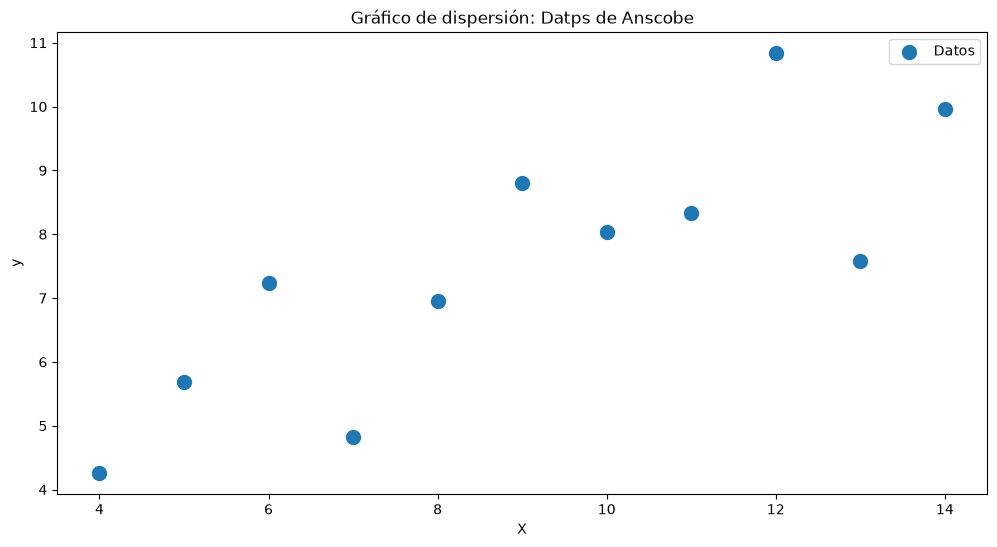

In [3]:
# Visualizamos

fig = plt.figure(figsize=(12,6))
plt.scatter(df["x"], df["y"], s=100, label="Datos")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Gráfico de dispersión: Datps de Anscobe")
plt.legend()
plt.show()

In [4]:
# Extraer variables en arrays
x = df["x"].values
y = df["y"].values

print("x", x)
print("y", y)
print(np.column_stack((x, y))) # Forma interesante de imprimir
print("---")

# Medias
x_mean = np.mean(x)
y_mean = np.mean(y)

print("x_mean", x_mean)
print("y_mean", y_mean)
print("---")

# Fórmulas OLS
beta_1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
beta_0 = y_mean - beta_1 * x_mean

print("beta_0", beta_0)
print("beta_1", beta_1)
print("---")

x [ 4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14.]
y [ 4.26  5.68  7.24  4.82  6.95  8.81  8.04  8.33 10.84  7.58  9.96]
[[ 4.    4.26]
 [ 5.    5.68]
 [ 6.    7.24]
 [ 7.    4.82]
 [ 8.    6.95]
 [ 9.    8.81]
 [10.    8.04]
 [11.    8.33]
 [12.   10.84]
 [13.    7.58]
 [14.    9.96]]
---
x_mean 9.0
y_mean 7.50090909090909
---
beta_0 3.0000909090909076
beta_1 0.5000909090909091
---


In [5]:
# Predecimos para cada x, un valor de y
# para comprobar que tal funciona nuestra formula

df["y_pred"] = beta_1 * df["x"] + beta_0
df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y,y_pred
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,4.26,5.000455
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,5.68,5.500545
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,7.24,6.000636
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,4.82,6.500727
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,6.95,7.000818


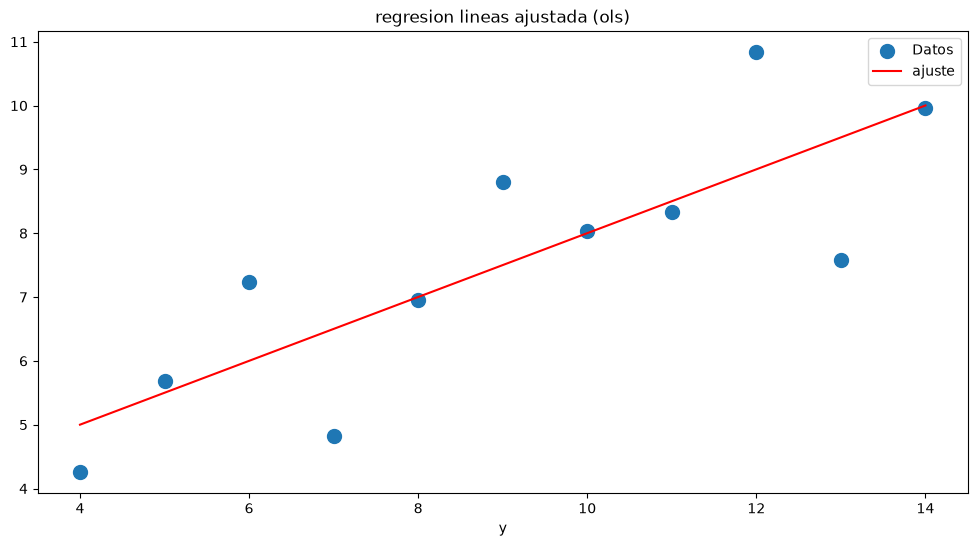

In [6]:
fig = plt.figure(figsize=(12, 6))

# Dibujar los datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Recta ajustada
plt.plot(df["x"], df["y_pred"], color="red", label="ajuste")

plt.xlabel("X")
plt.xlabel("y")
plt.title("regresion lineas ajustada (ols)")
plt.legend()
plt.show()

In [7]:
X = np.column_stack((np.ones(len(df["x"])), df["x"]))
print(X)

y_vec = df["y"].values

betas = np.linalg.inv(X.T @ X) @ X.T @ y_vec

print("betas[0]", betas[0])
print("betas[1]", betas[1])

[[ 1.  4.]
 [ 1.  5.]
 [ 1.  6.]
 [ 1.  7.]
 [ 1.  8.]
 [ 1.  9.]
 [ 1. 10.]
 [ 1. 11.]
 [ 1. 12.]
 [ 1. 13.]
 [ 1. 14.]]
betas[0] 3.000090909090903
betas[1] 0.5000909090909095
